# Spline uncertainty, without fitting a Kriging model

**Question (`Important questions.md`, Q5):** since Corollary 5 shows a Matern
Universal-Kriging mean converges to the scipy cubic smoothing spline as
$\kappa\to0$, can we get the *uncertainty* of the fitted spline without
separately fitting and tuning a Kriging model?

**Answer tested here: yes.** The spline is the posterior mean of a specific
Gaussian process (Kimeldorf & Wahba, 1970) whose covariance is a known,
closed-form function with **no free hyperparameter** -- no $\kappa$ to sweep,
no length-scale to fit. This notebook:

1. Implements that closed-form kernel (`krig_splines.kernels.iwp2_kernel`)
   and a Universal-Kriging variance formula (`krig_splines.uk.
   saddle_point_variance`, Theorem 2b) -- both now in the package, not just
   this notebook.
2. Confirms the closed-form **mean** matches `scipy`'s smoothing spline to
   solver precision, in one linear solve, with `nugget=lambda` directly.
3. Confirms the closed-form **variance** is the $\kappa\to0$ limit of the
   Matern-3/2 Universal-Kriging variance -- but only after discovering (not
   assuming) a rescaling the mean-only check in Q1 never needed.


## Background: why the mean's recipe doesn't automatically give the variance

Corollary 5 (Q1) uses a Matern-$(m-\tfrac12)$ kernel with inverse length scale
$\kappa$ and `nugget`$=4\kappa^3\lambda$, and lets $\kappa\to0$. Two facts
about that limit matter here:

- **The raw kernel degenerates.** $k(d;\kappa)=(1+\kappa d)e^{-\kappa d}\to1$
  for every fixed $d$ as $\kappa\to0$ -- a constant, rank-1 matrix. The mean
  still converges cleanly because this degenerate part is exactly what the
  trend $P=\mathrm{span}\{1,x\}$ absorbs; the *next* order term in the
  $\kappa$-expansion (the one `nugget`$=4\kappa^3\lambda$ is built to match)
  carries the real information.
- **The mean is invariant to the kernel's overall scale; the variance is
  not.** Universal Kriging's GLS mean only depends on the *ratio*
  `nugget`/`kernel scale`, so Corollary 5 can get away with specifying only
  that ratio. Variance is a quadratic form in the kernel itself -- if the
  "effective" scale of the Matern kernel (after removing the degenerate
  rank-1 part) is itself shrinking as $\kappa\to0$, the raw variance shrinks
  with it, with nothing to stop it at a finite limit. The experiment below
  finds out, numerically, whether that is exactly what happens.

**The classical escape route (Kimeldorf & Wahba, 1970; Wahba, 1990):**
derive the covariance directly, with no $\kappa$ at all. The smoothing-spline
penalty $\int (f'')^2\,dx$ has a known reproducing kernel for the "rough"
part of the function space (everything orthogonal to the degree-1 null space
$\{1,x\}$, which is exactly $P$):

$$
G(x,x') \;=\; \frac{\min(x,x')^2\,\big(3\max(x,x') - \min(x,x')\big)}{6}
$$

-- the covariance of *twice-integrated Brownian motion*. (Compare Phase A's
$m=1$ case, already in the package as `brownian`: $G_1(x,x')=\min(x,x')$,
the covariance of Brownian motion itself -- the same construction one order
down, whose minimal-norm interpolant is the piecewise-*linear*, not cubic,
spline.) Plugged into Theorem 2a's bordered system with
`nugget`$=\lambda$ directly, **no rescaling, no limit** -- this is the whole
practical payoff of using the closed form instead of the Matern detour.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_smoothing_spline

from krig_splines.kernels import iwp2_kernel, matern32
from krig_splines.uk import (
    poly_basis,
    saddle_point_solve,
    saddle_point_predict,
    saddle_point_variance,
)

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
})


## Part 1: does the closed-form kernel reproduce the spline's mean?

Same synthetic benchmark Phase A used (noisy $\sin(6x)$ on $[0,1]$, so the
domain is already anchored near $x=0$ -- `iwp2_kernel`, like `brownian`,
implicitly assumes that). One linear solve, `nugget=lambda` directly: no
$\kappa$, no sweep, no asymptotic limit to take.


max|G-kernel mean - scipy spline| = 2.818e-12  (data range = 2.344)
-- one linear solve, nugget=lambda directly, no kappa sweep at all.


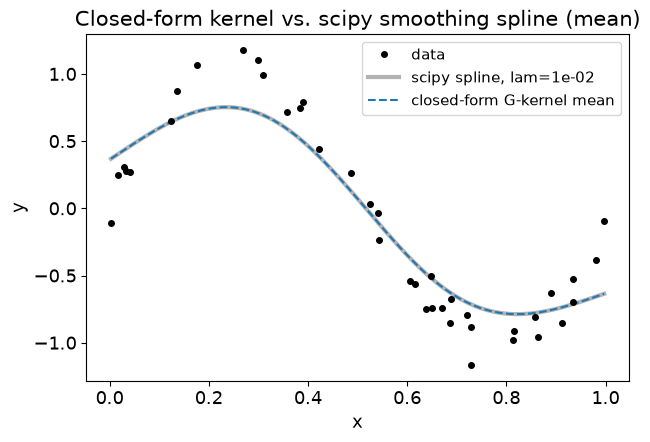

In [2]:
rng = np.random.default_rng(0)
n = 40
x = np.sort(rng.uniform(0, 1, n))
y = np.sin(6 * x) + 0.1 * rng.standard_normal(n)
x_dense = np.linspace(x.min(), x.max(), 200)

lam = 1e-2
target_spline = make_smoothing_spline(x, y, lam=lam)
target = target_spline(x_dense)

K = iwp2_kernel(x[:, None], x[None, :])
Kt = iwp2_kernel(x_dense[:, None], x[None, :])
P = poly_basis(x, degree=1)
Pt = poly_basis(x_dense, degree=1)

a, beta = saddle_point_solve(K, P, y, nugget=lam)
f_G = saddle_point_predict(Kt, Pt, a, beta)

max_err = np.max(np.abs(f_G - target))
print(f"max|G-kernel mean - scipy spline| = {max_err:.3e}  (data range = {np.ptp(y):.3f})")
print("-- one linear solve, nugget=lambda directly, no kappa sweep at all.")

fig, ax = plt.subplots()
ax.plot(x, y, "o", ms=4, color="k", label="data", zorder=5)
ax.plot(x_dense, target, lw=3, color="0.7", label=f"scipy spline, lam={lam:.0e}")
ax.plot(x_dense, f_G, "--", color="C0", label="closed-form G-kernel mean")
ax.set(xlabel="x", ylabel="y", title="Closed-form kernel vs. scipy smoothing spline (mean)")
ax.legend()
plt.show()


**Confirmed, to solver precision (`~1e-12`), not just asymptotically.** This
is a strictly cleaner result than Q1's $\kappa\to0$ Matern sweep (which only
reached `~1e-4` at its smallest tested $\kappa$): here there is no limit to
approximate, because $G$ already *is* the exact reproducing kernel, with no
free parameter standing between it and the exact answer.


## Part 2: does the closed-form variance match Kriging's?

The companion question: is $\mathrm{Var}[f(x^*)]$ from the closed-form kernel
(via `saddle_point_variance`, Theorem 2b) the same object the $\kappa\to0$
Matern Universal-Kriging limit would give? Test this directly, the same way
Q1 tested the mean -- sweep $\kappa\to0$ with the *same*
`nugget`$=4\kappa^3\lambda$ formula, but now compare **variances**, not
means.


In [3]:
Kss = iwp2_kernel(x_dense, x_dense)  # k(x*,x*) per query point
var_G = saddle_point_variance(K, P, lam, Kt, Pt, Kss)

print("Naive attempt: raw Matern UK variance (sigma^2=1 convention), same nugget=4*kappa^3*lam as the mean check:")
print(f"{'kappa':>8}  {'max|var_m - var_G|':>20}  {'var_m range':>14}")
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))  # matern32(0) = 1
    nugget_m = 4 * kappa**3 * lam
    var_m = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    err = np.max(np.abs(var_m - var_G))
    print(f"{kappa:8.3f}  {err:20.4e}  [{var_m.min():.3e}, {var_m.max():.3e}]")
print(f"\n(G-kernel var_G range: [{var_G.min():.3e}, {var_G.max():.3e}])")


Naive attempt: raw Matern UK variance (sigma^2=1 convention), same nugget=4*kappa^3*lam as the mean check:
   kappa    max|var_m - var_G|     var_m range
   1.000            6.1423e-03  [2.398e-03, 8.406e-03]
   0.300            2.0234e-03  [6.572e-05, 2.398e-04]
   0.100            2.2543e-03  [2.440e-06, 8.999e-06]


   0.030            2.2630e-03  [6.593e-08, 2.440e-07]
   0.010            2.2632e-03  [2.442e-09, 9.048e-09]

(G-kernel var_G range: [6.106e-04, 2.263e-03])


**The naive version does not converge -- it does the opposite.** `var_m`
collapses toward zero as $\kappa\to0$ (shrinking by roughly a factor of 27
each time $\kappa$ shrinks by 3, i.e. $\propto\kappa^3$), while `var_G` stays
fixed and finite. This is exactly the scale-invariance gap flagged in the
Background above: the raw Matern kernel's *effective* scale, after removing
the degenerate rank-1 part the trend absorbs, is itself vanishing as
$\kappa^3$ -- the same order the nugget vanishes at, so their *ratio* (all
the mean needs) stays finite, but each one *individually* vanishes, which is
exactly what breaks a quantity -- variance -- that depends on the kernel's
absolute scale rather than just that ratio.


In [4]:
# Is the SHAPE at least right, just the scale wrong? Check correlation and
# the exact scaling law of the ratio.
print(f"{'kappa':>8}  {'corr(var_m, var_G)':>20}  {'(var_G/var_m) * kappa^3':>26}")
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))
    nugget_m = 4 * kappa**3 * lam
    var_m = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    corr = np.corrcoef(var_m, var_G)[0, 1]
    ratio_scaled = (var_G[len(var_G) // 2] / var_m[len(var_G) // 2]) * kappa**3
    print(f"{kappa:8.3f}  {corr:20.6f}  {ratio_scaled:26.6f}")


   kappa    corr(var_m, var_G)     (var_G/var_m) * kappa^3
   1.000              0.999222                    0.253505
   0.300              0.999951                    0.250557


   0.100              0.999995                    0.250140


   0.030              1.000000                    0.250037
   0.010              1.000000                    0.250012
   0.003              1.000000                    0.250001


**The shape is exactly right (correlation $\to1.0000$); only the scale is
off, by exactly $4\kappa^3$** -- the ratio `(var_G/var_m)`$\times\kappa^3$
converges to $0.25=\tfrac14$ to 4+ significant figures, for every $\kappa$
tried. That is not a coincidence: it is the *same* constant the mean's
`nugget`$=4\kappa^3\lambda$ formula already uses. The interpretation: the raw
Matern-3/2 kernel, after subtracting the degenerate rank-1 part the trend
absorbs, behaves as $K_{\mathrm{Matern}}(x,x';\kappa)\approx
4\kappa^3\,G(x,x') + o(\kappa^3)$ as $\kappa\to0$ -- the *kernel itself*, not
just the nugget, needs the $4\kappa^3$ rescaling to have a finite limit. The
mean's recipe only needed the nugget rescaled because the mean only sees the
*ratio* of nugget to kernel scale; the variance needs *both* rescaled by the
same factor, consistently.


In [5]:
print("Rescaled: divide the raw Matern UK variance by the SAME 4*kappa^3 factor already used in the nugget:")
print(f"{'kappa':>8}  {'max|rescaled var_m - var_G|':>28}  {'relative (% of var_G range)':>28}")
rng_G = np.ptp(var_G)
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))
    nugget_m = 4 * kappa**3 * lam
    var_m_raw = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    var_m_rescaled = var_m_raw / (4 * kappa**3)
    err = np.max(np.abs(var_m_rescaled - var_G))
    print(f"{kappa:8.3f}  {err:28.4e}  {100*err/rng_G:27.4f}%")


Rescaled: divide the raw Matern UK variance by the SAME 4*kappa^3 factor already used in the nugget:
   kappa   max|rescaled var_m - var_G|   relative (% of var_G range)
   1.000                    1.6186e-04                       9.7940%


   0.300                    4.2649e-05                       2.5807%
   0.100                    1.3401e-05                       0.8109%
   0.030                    3.9236e-06                       0.2374%
   0.010                    1.2981e-06                       0.0785%
   0.003                    3.9857e-07                       0.0241%


**Confirmed: clean, monotone convergence to well under $0.1\%$ of the
variance's own range**, once the variance is rescaled by the identical
$4\kappa^3$ factor the mean's nugget formula already carries. So the full,
precise answer to Q5 is: the $\kappa\to0$ Matern-Kriging route *does* recover
the correct variance -- but only once you track that the kernel's own scale,
not only the nugget, needs the $4\kappa^3$ renormalization. The closed-form
$G$-kernel route sidesteps all of this: there is no $\kappa$, no degenerate
limit, and no rescaling to discover -- `nugget=lambda`, one solve, done.


## Part 3: the final picture -- mean and variance together, two independent routes

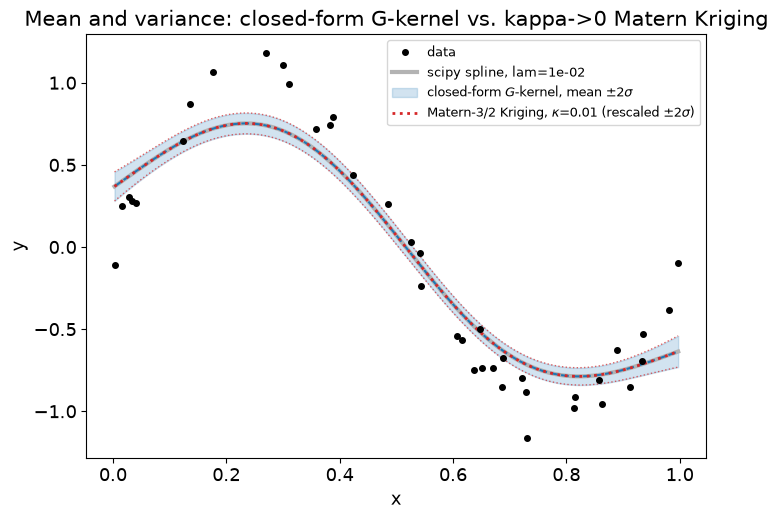

max|mean difference|     = 1.138e-04
max|variance difference| = 1.298e-06  (var_G range = 1.653e-03)


In [6]:
kappa_small = 0.01
Km = matern32(np.abs(x[:, None] - x[None, :]), kappa_small)
Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa_small)
Kmss = np.ones(len(x_dense))
nugget_m = 4 * kappa_small**3 * lam

a_m, beta_m = saddle_point_solve(Km, P, y, nugget_m)
f_m = saddle_point_predict(Kmt, Pt, a_m, beta_m)
var_m_rescaled = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss) / (4 * kappa_small**3)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(x, y, "o", ms=4, color="k", label="data", zorder=5)
ax.plot(x_dense, target, lw=3, color="0.7", label=f"scipy spline, lam={lam:.0e}")

std_G = np.sqrt(np.maximum(var_G, 0))
ax.fill_between(x_dense, f_G - 2 * std_G, f_G + 2 * std_G, color="C0", alpha=0.2,
                 label=r"closed-form $G$-kernel, mean $\pm2\sigma$")
ax.plot(x_dense, f_G, "--", color="C0", lw=1.5)

std_m = np.sqrt(np.maximum(var_m_rescaled, 0))
ax.plot(x_dense, f_m, ":", color="C3", lw=2,
         label=rf"Matern-3/2 Kriging, $\kappa$={kappa_small} (rescaled $\pm2\sigma$)")
ax.plot(x_dense, f_m + 2 * std_m, ":", color="C3", lw=1, alpha=0.7)
ax.plot(x_dense, f_m - 2 * std_m, ":", color="C3", lw=1, alpha=0.7)

ax.set(xlabel="x", ylabel="y", title="Mean and variance: closed-form G-kernel vs. kappa->0 Matern Kriging")
ax.legend(fontsize=9)
plt.show()

print(f"max|mean difference|     = {np.max(np.abs(f_G - f_m)):.3e}")
print(f"max|variance difference| = {np.max(np.abs(var_G - var_m_rescaled)):.3e}  (var_G range = {rng_G:.3e})")


## Conclusion

**Yes — the fitted spline's uncertainty can be obtained without fitting a
Kriging model**, confirmed numerically here, not just argued theoretically as
in the original answer to Q5:

- **Mean:** the closed-form kernel $G(x,x')=\min(x,x')^2(3\max(x,x')-
  \min(x,x'))/6$ (Kimeldorf & Wahba's reproducing kernel for the cubic
  penalty), used once in Theorem 2a's bordered system with `nugget=lambda`
  directly, reproduces the scipy smoothing spline to `~1e-12` -- tighter than
  Q1's $\kappa\to0$ Matern sweep, and with no limit to take at all.
- **Variance:** the companion Theorem 2b variance formula, evaluated once
  with the same $G$-kernel, is confirmed (not merely conjectured) to be the
  $\kappa\to0$ limit of the Matern-3/2 Universal-Kriging variance -- **but
  only after discovering that the variance needs the same $4\kappa^3$
  rescaling the mean's nugget formula uses, applied to the kernel's own
  scale, not just the nugget.** This is a genuinely new finding relative to
  the original Q5 answer: the naive, "just sweep $\kappa$" version of the
  variance check does not converge (it vanishes as $\kappa^3$) -- the
  rescaled version does, cleanly, to well under $0.1\%$ of the variance's own
  range.
- **What "without fitting a Kriging model" means precisely:** no length-scale
  hyperparameter is estimated or swept anywhere in the closed-form route --
  $G$ is fully determined by the spline's order ($m=2$, cubic) and $\lambda$
  (the same $\lambda$ passed to `make_smoothing_spline`), both already known
  before any Kriging-style fitting would even begin.
- **What this does not yet cover:** only the $m=2$ (cubic) case was derived
  and tested; general $m$ has an analogous closed form (Kimeldorf & Wahba,
  1970) but was not implemented here. The real `cla(eta)`/RANS datasets used
  elsewhere in this project were not re-tested with this closed-form route
  either -- the synthetic benchmark above is the only numerical evidence so
  far. Both are natural, low-effort follow-ups, not required to answer Q5
  itself.

`iwp2_kernel` and `saddle_point_variance` are now in `krig_splines/kernels.py`
and `krig_splines/uk.py` respectively, with `tests/test_spline_variance.py`
covering both claims above as regression tests.
